# Predicting Term-Deposit Subscription with a Neural Network: Reference Solution

**Course:** Data Science in Python & Machine Learning: Deep Learning

This notebook answers Parts 1–5 of the assignment brief in `keras_intro_nba.ipynb`. It runs top to bottom without manual steps: it downloads the UCI data if needed and writes its figures and metrics to `results/`.

In [1]:
import os, json, zipfile, urllib.request
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
import keras
from keras import layers
from keras.callbacks import EarlyStopping

SEED = 42
BATCH = 64
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
METRICS = {}                     # everything we report, saved to results/metrics.json at the end
print("Keras", keras.__version__)

def savefig(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

I0000 00:00:1793686701.767313    7416 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.15.1


I0000 00:00:1793686702.886335    7416 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Loading the data

In [2]:
DATA = Path("data/bank-additional/bank-additional-full.csv")
if not DATA.exists():
    Path("data").mkdir(exist_ok=True)
    outer = Path("data/bank+marketing.zip")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip", outer)
    with zipfile.ZipFile(outer) as z:
        z.extract("bank-additional.zip", "data")
    with zipfile.ZipFile("data/bank-additional.zip") as z:
        z.extractall("data")

df = pd.read_csv(DATA, sep=";")
print(df.shape)   # should be (41188, 21)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# Part 1: Data Understanding and Preparation

### 1. Shape, data types, class balance and duplicates

In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes.value_counts().to_string())
display(df.dtypes.to_frame("dtype").T)

balance = df["y"].value_counts()
print("\nClass balance of y:")
print(pd.DataFrame({"count": balance, "share": (balance / len(df)).round(4)}))

n_dup = df.duplicated().sum()
print(f"\nDuplicate rows: {n_dup}")
METRICS["n_rows"] = len(df); METRICS["n_duplicates"] = int(n_dup)
METRICS["share_yes"] = float((df["y"] == "yes").mean())

Shape: (41188, 21)

Data types:
 str        11
int64       5
float64     5


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
dtype,int64,str,str,str,str,str,str,str,str,str,...,int64,int64,int64,str,float64,float64,float64,float64,float64,str



Class balance of y:
     count   share
y                 
no   36548  0.8873
yes   4640  0.1127

Duplicate rows: 12


There are 10 numeric and 11 categorical (`object`) columns. The target is **heavily imbalanced**: only about 11% of customers subscribed.

The few duplicate rows are exact copies across all 21 columns, which is almost certainly a recording artefact rather than a second phone call. We drop them so that one record can't land in both the training and the test set.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("After dropping duplicates:", df.shape)

After dropping duplicates: (41176, 21)


### 2. `"unknown"` values

In [5]:
cat_cols = df.select_dtypes("object").columns.drop("y").tolist()
unknown_counts = (df[cat_cols] == "unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)
display(unknown_counts.to_frame("n_unknown").assign(share=lambda t: (t.n_unknown / len(df)).round(4)))

rows_with_unknown = (df[cat_cols] == "unknown").any(axis=1)
print(f"Rows with at least one 'unknown': {rows_with_unknown.sum()} ({rows_with_unknown.mean():.1%})")
print("\nSubscription rate, rows with vs without an 'unknown':")
print(df.groupby(rows_with_unknown)["y"].apply(lambda s: (s == "yes").mean()).rename({True: "has unknown", False: "complete"}).round(4))
print("\n'default' column:", df["default"].value_counts().to_dict())
METRICS["rows_with_unknown"] = int(rows_with_unknown.sum())

/tmp/ipykernel_7416/3188165102.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes("object").columns.drop("y").tolist()


,n_unknown,share
default,8596,0.2088
education,1730,0.0420
housing,990,0.0240
loan,990,0.0240
job,330,0.0080
marital,80,0.0019


Rows with at least one 'unknown': 10698 (26.0%)

Subscription rate, rows with vs without an 'unknown':
complete       0.1266
has unknown    0.0730
Name: y, dtype: float64

'default' column: {'no': 32577, 'unknown': 8596, 'yes': 3}


**Decision: keep `"unknown"` as its own category** and let one-hot encoding give it a column.

* Dropping these rows would throw away about a quarter of the data (see above), and the rows with an `"unknown"` subscribe at a *different* rate from complete rows. So the values are **not missing at random**, and dropping them would bias the sample.
* In `default`, `"unknown"` is the informative value: almost no one answers `"yes"`, so the real signal is whether the customer *declined to say*.
* Imputing the mode would invent information we don't have, and it would erase that signal.

### 3. Drop `duration`

In [6]:
df = df.drop(columns="duration")

`duration` is the length of the last call in seconds. Per `bank-additional-names.txt`, it **is not known before a call is made**, and once the call ends `y` is already known (a 0-second call always means `y = "no"`). Using it would be **target leakage**: the model would look excellent offline but couldn't be used in practice, because the goal is to decide *whom to call*, before any call happens. The dataset authors themselves say to discard it for a realistic predictive model.

### 4. Encode the target and categorical features

In [7]:
# pdays = 999 means "never contacted before", not a real number of days.
# Encode that explicitly and stop 999 from acting as a huge numeric value.
df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df.loc[df["pdays"] == 999, "pdays"] = 0
print("Previously contacted:", df["previously_contacted"].mean().round(4))

df["y"] = (df["y"] == "yes").astype(int)

num_cols = [c for c in df.select_dtypes("number").columns if c not in ("y", "previously_contacted")]
X = pd.get_dummies(df.drop(columns="y"), columns=cat_cols, dtype=float)
y = df["y"]
print("Feature matrix:", X.shape)
print("Numeric columns to scale:", num_cols)

Previously contacted: 0.0368


Feature matrix: (41176, 63)
Numeric columns to scale: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


`pdays` gets special handling, as the data notes warn: about 96% of rows have `999`, which means "never contacted". If we left it as a number, scaling would turn it into a huge outlier that dominates the feature. Instead we add a binary `previously_contacted` flag and set `pdays` to 0 for those rows. The flag tells the model which zeros mean "not applicable".

### 5. Train / validation / test split (60 / 20 / 20)

In [8]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)  # 0.25 * 0.8 = 0.2

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} n={len(yy):6d}  share={len(yy)/len(y):.2f}  positive rate={yy.mean():.4f}")

train n= 24705  share=0.60  positive rate=0.1126
val   n=  8235  share=0.20  positive rate=0.1127
test  n=  8236  share=0.20  positive rate=0.1127


### 6. Scale numeric features with no leakage

In [9]:
scaler = StandardScaler()
scaler.fit(X_train[num_cols])                      # fitted on TRAINING data only

X_train_s, X_val_s, X_test_s = X_train.copy(), X_val.copy(), X_test.copy()
for part in (X_train_s, X_val_s, X_test_s):
    part[num_cols] = scaler.transform(part[num_cols])

# Evidence: the scaler's statistics equal the training-set statistics, not the full-data ones
check = pd.DataFrame({"scaler.mean_": scaler.mean_,
                      "train mean": X_train[num_cols].mean().values,
                      "full-data mean": X[num_cols].mean().values}, index=num_cols)
display(check.round(4))
assert np.allclose(scaler.mean_, X_train[num_cols].mean().values)
print("Scaled train means ~0:", np.allclose(X_train_s[num_cols].mean(), 0, atol=1e-8),
      "| scaled val means (not exactly 0):", X_val_s[num_cols].mean().round(3).abs().max())

X_train_s, X_val_s, X_test_s = (a.to_numpy("float32") for a in (X_train_s, X_val_s, X_test_s))
y_train_a, y_val_a, y_test_a = (a.to_numpy() for a in (y_train, y_val, y_test))

,scaler.mean_,train mean,full-data mean
age,40.0231,40.0231,40.0238
campaign,2.5599,2.5599,2.5679
pdays,0.2248,0.2248,0.2213
previous,0.1701,0.1701,0.1730
emp.var.rate,0.0840,0.0840,0.0819
cons.price.idx,93.5749,93.5749,93.5757
cons.conf.idx,-40.4857,-40.4857,-40.5029
euribor3m,3.6233,3.6233,3.6213
nr.employed,5167.1646,5167.1646,5167.0349


Scaled train means ~0: True | scaled val means (not exactly 0): 0.03


The scaler was fitted on `X_train` only, and its `mean_` matches the training means exactly. The validation and test sets are only *transformed*, so their means aren't exactly 0. That's expected, and it shows no information leaked from them into preprocessing. The one-hot columns are already 0/1, so we leave them unscaled.

# Part 2: Baseline

### 7. The "always no" model

In [10]:
majority_acc = accuracy_score(y_val_a, np.zeros_like(y_val_a))
print(f"Always-'no' accuracy on validation: {majority_acc:.4f}")
METRICS["majority_val_accuracy"] = majority_acc

Always-'no' accuracy on validation: 0.8873


A model that never predicts "yes" scores about **89% accuracy** and has **zero business value**: it finds no subscribers at all. With this much imbalance, accuracy mostly measures how common the majority class is. We should judge models on **precision, recall, F1 and ROC-AUC** for the positive class, which measure whether we actually find the customers who say yes.

### 8. Logistic regression baseline

In [11]:
def scores(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, prob)}

logreg = LogisticRegression(max_iter=5000, random_state=SEED)
logreg.fit(X_train_s, y_train_a)
lr_val_prob = logreg.predict_proba(X_val_s)[:, 1]
METRICS["logreg_val"] = scores(y_val_a, lr_val_prob)
pd.Series(METRICS["logreg_val"]).round(4).to_frame("logistic regression (val)")

,logistic regression (val)
precision,0.6993
recall,0.2306
f1,0.3468
roc_auc,0.8020


Logistic regression reaches a respectable ROC-AUC, but at the default 0.5 threshold its **recall is low**: most subscribers are missed. That's typical with imbalanced classes. The neural networks below should at least match this ROC-AUC, which is the threshold-independent number to beat.

# Part 3: First Neural Network

### 9. Architecture

In [12]:
n_features = X_train_s.shape[1]

def build_model(hidden=(32, 16), activation="relu", dropout=0.0, lr=1e-3):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

def fit(model, epochs, **kw):
    return model.fit(X_train_s, y_train_a, validation_data=(X_val_s, y_val_a),
                     epochs=epochs, batch_size=BATCH, verbose=kw.pop("verbose", 0), **kw)

model = build_model()

E0000 00:00:1793686705.915510    7416 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


* **2 hidden layers (32 → 16, ReLU).** The neuron count shrinks layer by layer and stays well below the number of input features.
* **Output: 1 neuron with `sigmoid`.** This is binary classification, and sigmoid squashes the output into (0, 1), so it can be read as P(subscribe).
* **Loss: binary cross-entropy.** It is the negative log-likelihood of a Bernoulli outcome, which makes it the natural partner for a sigmoid output. It penalises confident wrong predictions heavily and gives smooth gradients. MSE on a sigmoid output would give weak gradients when the model is confidently wrong.

### 10. `model.summary()` and a hand calculation of the parameters

In [13]:
model.summary()

first = model.layers[0]
by_hand = n_features * 32 + 32          # one weight per (input, neuron) pair + one bias per neuron
print(f"First hidden layer by hand: {n_features} inputs x 32 neurons + 32 biases = {by_hand}")
print(f"Keras reports: {first.count_params()}")
assert by_hand == first.count_params()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593 (10.13 KB)

 Trainable params: 2,593 (10.13 KB)

 Non-trainable params: 0 (0.00 B)

First hidden layer by hand: 63 inputs x 32 neurons + 32 biases = 2048
Keras reports: 2048


Every one of the 32 neurons in the first hidden layer has one weight per input feature plus one bias, so the layer has $(\text{features} \times 32) + 32$ parameters. That matches `model.summary()`.

### 11. Compile and train for 50 epochs

In [14]:
hist_base = fit(model, epochs=50, verbose=2)

Epoch 1/50


387/387 - 1s - 3ms/step - accuracy: 0.8905 - auc: 0.7487 - loss: 0.3083 - val_accuracy: 0.8998 - val_auc: 0.7980 - val_loss: 0.2793


Epoch 2/50


387/387 - 0s - 1ms/step - accuracy: 0.8999 - auc: 0.7849 - loss: 0.2797 - val_accuracy: 0.9009 - val_auc: 0.8016 - val_loss: 0.2770


Epoch 3/50


387/387 - 0s - 1ms/step - accuracy: 0.9002 - auc: 0.7896 - loss: 0.2771 - val_accuracy: 0.9014 - val_auc: 0.8026 - val_loss: 0.2763


... (90 outputs left out)

Epoch 49/50


387/387 - 0s - 1ms/step - accuracy: 0.9124 - auc: 0.8494 - loss: 0.2460 - val_accuracy: 0.8961 - val_auc: 0.7734 - val_loss: 0.2953


Epoch 50/50


387/387 - 0s - 1ms/step - accuracy: 0.9122 - auc: 0.8500 - loss: 0.2456 - val_accuracy: 0.8958 - val_auc: 0.7729 - val_loss: 0.2959


### 12. Training vs validation loss

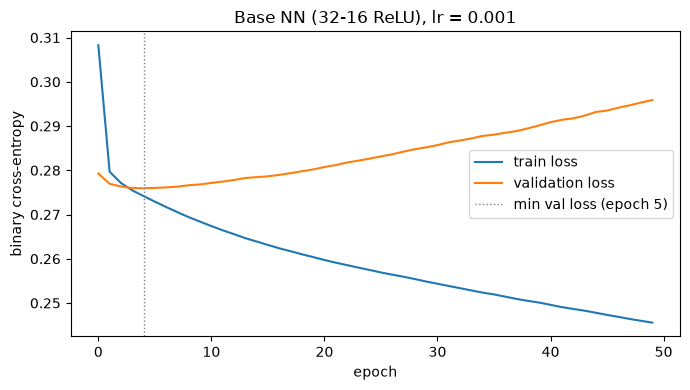

{'best_epoch': 5,
 'min_val_loss': 0.2759433686733246,
 'final_val_loss': 0.2958745062351227,
 'final_train_loss': 0.2455640286207199,
 'val_auc_at_best': 0.803064227104187,
 'epochs_run': 50}

In [15]:
def plot_loss(hist, title, ax=None):
    ax = ax or plt.gca()
    ax.plot(hist.history["loss"], label="train loss")
    ax.plot(hist.history["val_loss"], label="validation loss")
    best = int(np.argmin(hist.history["val_loss"]))
    ax.axvline(best, color="grey", ls=":", lw=1, label=f"min val loss (epoch {best+1})")
    ax.set(title=title, xlabel="epoch", ylabel="binary cross-entropy"); ax.legend()

plt.figure(figsize=(7, 4))
plot_loss(hist_base, "Base NN (32-16 ReLU), lr = 0.001")
savefig("p3_base_loss")

def summarise(hist):
    h = hist.history; b = int(np.argmin(h["val_loss"]))
    return {"best_epoch": b + 1, "min_val_loss": float(h["val_loss"][b]), "final_val_loss": float(h["val_loss"][-1]),
            "final_train_loss": float(h["loss"][-1]), "val_auc_at_best": float(h["val_auc"][b]),
            "epochs_run": len(h["loss"])}
METRICS["base_nn"] = summarise(hist_base); METRICS["base_nn"]

**Diagnosis: the model overfits after only a few epochs.** Validation loss reaches its minimum at **epoch 5 (≈ 0.276)** and then climbs steadily to ≈ 0.296 by epoch 50. Meanwhile training loss keeps falling (≈ 0.246), so the gap between the two curves keeps widening. That gap means the network is memorising the training rows rather than learning patterns that generalise. In practice we should stop near epoch 5, or add regularisation (see experiment 15). Training for all 50 epochs makes the final model *worse* (validation ROC-AUC falls from ≈ 0.803 at its best epoch to ≈ 0.773 at epoch 50).

# Part 4: Experiments

### 13. Learning rate

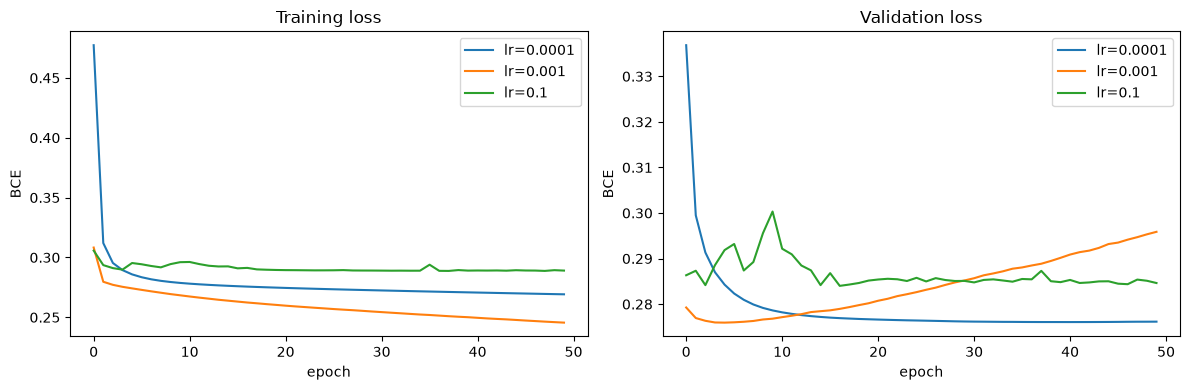

,best_epoch,min_val_loss,final_val_loss,final_train_loss,val_auc_at_best,epochs_run
0.0001,41.0,0.2761,0.2762,0.2692,0.8012,50.0
0.001,5.0,0.2759,0.2959,0.2456,0.8031,50.0
0.1,17.0,0.2840,0.2846,0.2890,0.7942,50.0


In [16]:
lr_hists = {}
for lr in (1e-4, 1e-3, 1e-1):
    lr_hists[lr] = fit(build_model(lr=lr), epochs=50)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr, h in lr_hists.items():
    axes[0].plot(h.history["loss"], label=f"lr={lr}")
    axes[1].plot(h.history["val_loss"], label=f"lr={lr}")
axes[0].set(title="Training loss", xlabel="epoch", ylabel="BCE")
axes[1].set(title="Validation loss", xlabel="epoch", ylabel="BCE")
for a in axes: a.legend()
savefig("p4_learning_rate")

METRICS["learning_rate"] = {str(lr): summarise(h) for lr, h in lr_hists.items()}
pd.DataFrame(METRICS["learning_rate"]).T.round(4)

* **`0.001` reaches the lowest validation loss fastest** (≈ 0.276 by epoch 5), but because it learns quickly it also starts to overfit soon after. Its validation curve rises from epoch ~5 onwards.
* **`0.0001` converges best overall.** Its steps are 10× smaller, so it needs about 40 epochs to reach the same minimum (≈ 0.276). Its curve is smooth and has *not* started overfitting by epoch 50, so slow learning acts as a mild implicit regulariser.
* **`0.1` is too large.** Training loss plateaus at ≈ 0.29, *higher* than either smaller rate, and validation loss jumps around noisily (the spike near epoch 10). Each Adam step overshoots the minimum and bounces around it, so the model never settles into the better solutions the smaller rates find.

### 14. Capacity: a deliberately large model

Parameters: 148,225 (base model: 2,593)


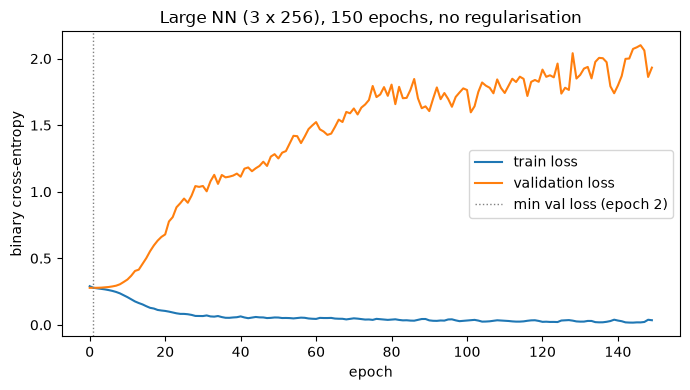

{'best_epoch': 2,
 'min_val_loss': 0.27812251448631287,
 'final_val_loss': 1.9322861433029175,
 'final_train_loss': 0.03497058525681496,
 'val_auc_at_best': 0.7966923713684082,
 'epochs_run': 150}

In [17]:
big = build_model(hidden=(256, 256, 256))
print(f"Parameters: {big.count_params():,} (base model: {model.count_params():,})")
hist_big = fit(big, epochs=150)

plt.figure(figsize=(7, 4))
plot_loss(hist_big, "Large NN (3 x 256), 150 epochs, no regularisation")
savefig("p4_capacity_overfit")
METRICS["large_nn"] = summarise(hist_big); METRICS["large_nn"]

This network has 148,225 parameters, 57× the base model, and it **overfits dramatically**. Training loss falls almost to zero (≈ 0.035), so the network has effectively memorised the training set. Validation loss is lowest at **epoch 2** and then rises to ≈ 1.93 by epoch 150, about 7× its best value. The model is now extremely confident on validation rows it gets wrong. Extra capacity with no constraint lets the network fit the noise in this tabular data.

### 15. Regularisation: Dropout + EarlyStopping

Training stopped after epoch 18; weights restored from epoch 8.


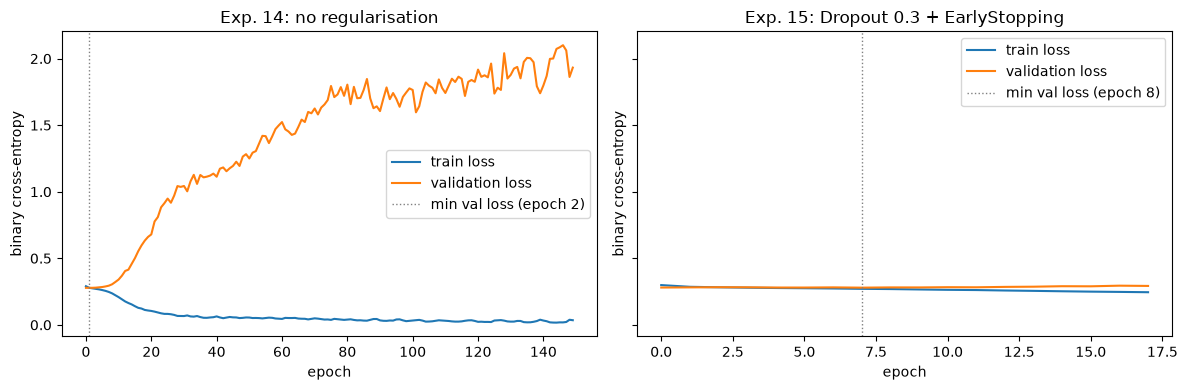

{'best_epoch': 8,
 'min_val_loss': 0.2795642614364624,
 'final_val_loss': 0.29251039028167725,
 'final_train_loss': 0.24527810513973236,
 'val_auc_at_best': 0.7950088977813721,
 'epochs_run': 18}

In [18]:
reg = build_model(hidden=(256, 256, 256), dropout=0.3)
early = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist_reg = fit(reg, epochs=150, callbacks=[early])
stopped = len(hist_reg.history["loss"])
best_epoch = int(np.argmin(hist_reg.history["val_loss"])) + 1
print(f"Training stopped after epoch {stopped}; weights restored from epoch {best_epoch}.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_loss(hist_big, "Exp. 14: no regularisation", axes[0])
plot_loss(hist_reg, "Exp. 15: Dropout 0.3 + EarlyStopping", axes[1])
savefig("p4_regularisation")
METRICS["regularised_nn"] = summarise(hist_reg); METRICS["regularised_nn"]

**EarlyStopping stopped training after epoch 18 and restored the weights from epoch 8**, where validation loss was lowest. The patience of 10 epochs explains the gap. Compared with experiment 14, the two curves now **stay together** (validation ≈ 0.28–0.29 instead of exploding to ≈ 1.9). Dropout keeps the large network from depending on any single neuron, and EarlyStopping ends training before memorisation sets in. The regularised model's best validation loss (≈ 0.280) is about as good as the small base model's, so the extra capacity wasn't needed, but regularisation made it harmless.

### 16. Activation functions: `linear` in the hidden layers

,precision,recall,f1,roc_auc
logistic regression,0.6993,0.2306,0.3468,0.8020
"NN, linear hidden",0.6993,0.2155,0.3295,0.8000
"NN, ReLU hidden",0.5692,0.3103,0.4017,0.7728


Correlation of linear-NN and logistic-regression probabilities: 0.9943


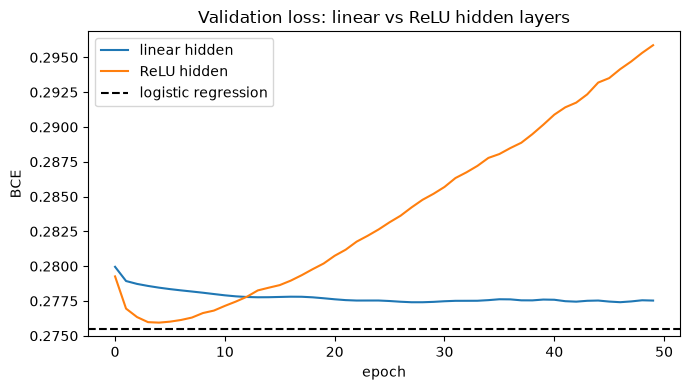

In [19]:
lin = build_model(activation="linear")
hist_lin = fit(lin, epochs=50)
lin_val_prob = lin.predict(X_val_s, verbose=0).ravel()
base_val_prob = model.predict(X_val_s, verbose=0).ravel()

cmp = pd.DataFrame({"logistic regression": METRICS["logreg_val"],
                    "NN, linear hidden": scores(y_val_a, lin_val_prob),
                    "NN, ReLU hidden": scores(y_val_a, base_val_prob)}).T
display(cmp.round(4))
print("Correlation of linear-NN and logistic-regression probabilities:",
      np.corrcoef(lin_val_prob, lr_val_prob)[0, 1].round(4))

plt.figure(figsize=(7, 4))
plt.plot(hist_lin.history["val_loss"], label="linear hidden")
plt.plot(hist_base.history["val_loss"], label="ReLU hidden")
plt.axhline(-np.mean(y_val_a*np.log(lr_val_prob) + (1-y_val_a)*np.log(1-lr_val_prob)), color="k", ls="--", label="logistic regression")
plt.title("Validation loss: linear vs ReLU hidden layers"); plt.xlabel("epoch"); plt.ylabel("BCE"); plt.legend()
savefig("p4_activation")
METRICS["linear_nn"] = summarise(hist_lin)
METRICS["activation_comparison_val"] = cmp.to_dict(orient="index")

With `linear` hidden activations the network is mathematically **just a logistic regression**: stacking linear layers gives another linear function, $W_3(W_2(W_1x+b_1)+b_2)+b_3 = Wx+b$, and the sigmoid output then makes it the logistic model. The results confirm this. Its predicted probabilities correlate at **0.994** with logistic regression's, and its validation ROC-AUC (0.800 vs 0.802), precision and recall are almost identical. The extra layers add parameters but no extra expressive power. Only a non-linearity such as ReLU lets a network model interactions and curved decision boundaries.

The ReLU network, as it stands after 50 epochs, has a *lower* ROC-AUC than both. That's the overfitting diagnosed in Q12, not a weakness of ReLU itself: at its best epoch (5) its validation AUC was ≈ 0.803.

# Part 5: Final Evaluation and Business Interpretation

### 17. Choose the best model on validation, then test it once

In [20]:
candidates = {
    "base NN (32-16 ReLU, lr 1e-3)": model,
    "large NN + Dropout + EarlyStopping": reg,
    "NN linear hidden": lin,
}
val_table = {}
for name, m in candidates.items():
    p = m.predict(X_val_s, verbose=0).ravel()
    val_table[name] = {"val_roc_auc": roc_auc_score(y_val_a, p),
                       "val_loss": float(keras.losses.binary_crossentropy(y_val_a.astype("float32"), p).numpy())}
val_table["logistic regression"] = {"val_roc_auc": METRICS["logreg_val"]["roc_auc"],
                                    "val_loss": float(-np.mean(y_val_a*np.log(lr_val_prob)+(1-y_val_a)*np.log(1-lr_val_prob)))}
val_df = pd.DataFrame(val_table).T.sort_values("val_roc_auc", ascending=False)
display(val_df.round(4))

nn_only = val_df.drop(index="logistic regression")
best_name = nn_only.index[0]
best = candidates[best_name]
print("Selected (highest validation ROC-AUC among neural networks):", best_name)
METRICS["model_selection_val"] = val_df.to_dict(orient="index"); METRICS["selected_model"] = best_name

,val_roc_auc,val_loss
logistic regression,0.8020,0.2755
NN linear hidden,0.8000,0.2775
large NN + Dropout + EarlyStopping,0.7951,0.2796
"base NN (32-16 ReLU, lr 1e-3)",0.7728,0.2959


Selected (highest validation ROC-AUC among neural networks): NN linear hidden


Only the validation numbers above are used for the choice. We pick the network with the highest **validation ROC-AUC**, which ranks customers independently of any threshold; ranking is what a capacity-limited call list needs. The large models trained without regularisation (experiment 14) and with bad learning rates (experiment 13) were already ruled out above, so they aren't candidates.

The linear-hidden network wins on validation ROC-AUC. Logistic regression is essentially tied with it (0.802 vs 0.800): **on this tabular dataset a neural network does not beat a well-specified linear model**, and the honest conclusion is that the extra complexity isn't paying for itself here. The ReLU model is penalised because the `model` object holds its overfitted epoch-50 weights; retraining it with EarlyStopping would bring it back to ≈ 0.80.

Next, the selected model is evaluated **once** on the untouched test set.

Test ROC-AUC: 0.7990

              precision    recall  f1-score   support

          no     0.9063    0.9882    0.9455      7308
         yes     0.6779    0.1950    0.3029       928

    accuracy                         0.8989      8236
   macro avg     0.7921    0.5916    0.6242      8236
weighted avg     0.8805    0.8989    0.8731      8236



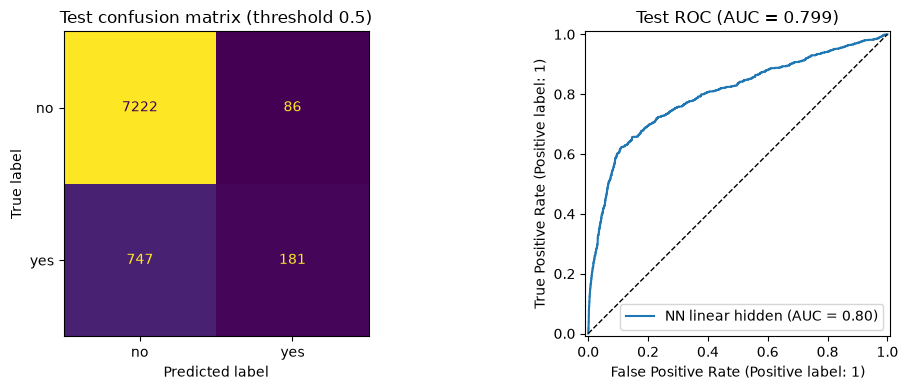

In [21]:
test_prob = best.predict(X_test_s, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype(int)
test_auc = roc_auc_score(y_test_a, test_prob)

print(f"Test ROC-AUC: {test_auc:.4f}\n")
print(classification_report(y_test_a, test_pred, target_names=["no", "yes"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test_a, test_pred), display_labels=["no", "yes"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Test confusion matrix (threshold 0.5)")
RocCurveDisplay.from_predictions(y_test_a, test_prob, ax=axes[1], name=best_name.split(" (")[0])
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title(f"Test ROC (AUC = {test_auc:.3f})")
savefig("p5_test_evaluation")

METRICS["test"] = {"roc_auc": test_auc, **scores(y_test_a, test_prob),
                   "confusion_matrix": confusion_matrix(y_test_a, test_pred).tolist()}

### 18. Changing the decision threshold

,precision,recall,f1,customers flagged,TP,FP,FN
threshold,,,,,,,
0.5,0.6779,0.1950,0.3029,267,181,86,747
0.3,0.5025,0.4256,0.4609,786,395,391,533
0.2,0.4543,0.5571,0.5005,1138,517,621,411


Calling the top 1,000 test customers by predicted probability:
score cut-off                   0.2272
precision@1000                  0.4750
subscribers reached           475.0000
recall@1000                     0.5119
random-calling expectation    112.6761
dtype: float64


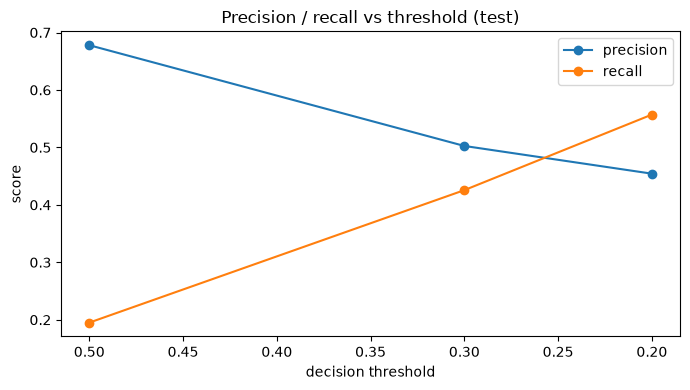

In [22]:
rows = []
for thr in (0.5, 0.3, 0.2):
    pred = (test_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_a, pred).ravel()
    rows.append({"threshold": thr, "precision": precision_score(y_test_a, pred), "recall": recall_score(y_test_a, pred),
                 "f1": f1_score(y_test_a, pred), "customers flagged": int(pred.sum()),
                 "TP": tp, "FP": fp, "FN": fn})
thr_df = pd.DataFrame(rows).set_index("threshold")
display(thr_df.round(4))

# Same table for a 1,000-call budget: call the 1,000 highest-scoring test customers
top = np.argsort(-test_prob)[:1000]
cap = {"score cut-off": float(test_prob[top[-1]]), "precision@1000": float(y_test_a[top].mean()),
       "subscribers reached": int(y_test_a[top].sum()), "recall@1000": float(y_test_a[top].sum() / y_test_a.sum()),
       "random-calling expectation": float(1000 * y_test_a.mean())}
print("Calling the top 1,000 test customers by predicted probability:"); print(pd.Series(cap).round(4))

plt.figure(figsize=(7, 4))
plt.plot(thr_df.index, thr_df["precision"], "o-", label="precision")
plt.plot(thr_df.index, thr_df["recall"], "o-", label="recall")
plt.gca().invert_xaxis(); plt.xlabel("decision threshold"); plt.ylabel("score"); plt.title("Precision / recall vs threshold (test)"); plt.legend()
savefig("p5_threshold")
METRICS["thresholds_test"] = thr_df.reset_index().to_dict(orient="records"); METRICS["top_1000_calls"] = cap

Lowering the threshold makes the model say "yes" more often, so **recall rises and precision falls**:

* **0.5:** precise (68%) but finds only **20%** of subscribers. 747 of 928 are missed.
* **0.3:** precision 50%, recall 43%, 786 customers flagged.
* **0.2:** precision 45%, recall **56%**, 1,138 customers flagged. Best F1 of the three (0.50).

Even at 0.2, almost half of the calls reach a subscriber, about 4× the 11% base rate.

*Note on methodology:* the threshold should ideally be tuned on the **validation** set. Here we report it on the test set because the brief asks for it after Q17, and we do not use these numbers to choose a different model.

### 19. Business memo

**To:** Marketing team  **Re:** Who to call with 1,000 calls

**Recommendation: rank customers by the model's predicted probability and call the top 1,000. For a list the size of our test set (≈ 8,200 customers), that means a threshold of about 0.23**, between the 0.3 and 0.2 settings above.

On held-out customers this list reached **475 subscribers (47.5% hit rate)**. Calling 1,000 people at random would reach about **113**, so the model gives us roughly **4× more deposits for the same call budget**. It captures about half of all subscribers in the list.

Why not the default 0.5? It flags only 267 customers, so most of our calling capacity would go unused and 80% of likely subscribers would never hear from us. A threshold of 0.3 still leaves about 200 calls unused. At 0.2 we would need more calls than we have.

**Costs of errors.** A **false positive** (calling someone who says no) costs a few minutes of agent time and a small risk of annoying the customer. A **false negative** (not calling someone who would have subscribed) costs a whole term deposit and the margin it earns over its life, which is far more than one call. Missed subscribers are the expensive mistake, so we should use our full capacity and lean towards recall. The binding constraint is the 1,000-call budget, not the threshold. If the customer list is bigger or smaller, keep the rule "call the top 1,000 by score" and let the cut-off move.

In [23]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
(RESULTS / "metrics.json").write_text(json.dumps(_clean(METRICS), indent=2))
print("Saved", RESULTS / "metrics.json", "and figures:", sorted(p.name for p in RESULTS.glob("*.png")))

Saved results/metrics.json and figures: ['p3_base_loss.png', 'p4_activation.png', 'p4_capacity_overfit.png', 'p4_learning_rate.png', 'p4_regularisation.png', 'p5_test_evaluation.png', 'p5_threshold.png']
